# Task 5: Machine Learning Classification Model

## Objective

The objective of this task is to build a machine learning classification model that predicts whether a Netflix title is a Movie or a TV Show based on available content features.

The analysis will focus on selecting meaningful features, preparing the data for machine learning, training classification models, evaluating their performance, and comparing the results.

The task follows five main steps:

1. Select and prepare features.
2. Split the data into training and testing sets.
3. Train classification models.
4. Evaluate model performance.
5. Compare model accuracy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df_ml = pd.read_csv("../data/netflix_clean.csv")

print("Dataset shape:", df_ml.shape)

Dataset shape: (8786, 26)


## Step 1: Select and prepare features

The target variable for this classification task is `type`, which identifies whether each Netflix title is a Movie or a TV Show.

I select features that could provide information about the characteristics of a title without directly revealing the target.

The selected features are:

- `release_year`
- `rating`
- `country`
- `listed_in`
- `director`
- `audience`
- `year_added`

I exclude identifiers such as `show_id` and `title` because they do not provide useful generalizable information for classification.

I also exclude `duration`, `movie_minutes`, and `tv_seasons`. These variables are closely tied to the content type and could allow the model to infer the target directly rather than learning from broader content characteristics.

In [2]:
target = "type"

feature_columns = [
    "release_year",
    "rating",
    "country",
    "listed_in",
    "director",
    "audience",
    "year_added"
]

X = df_ml[feature_columns].copy()
y = df_ml[target].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(3))

Feature shape: (8786, 7)
Target shape: (8786,)

Target distribution:
type
Movie      6123
TV Show    2663
Name: count, dtype: int64

Target proportions:
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64


### Inspect missing values

The selected features contain categorical fields with missing values, particularly `director` and `country`.

Rather than removing these rows, missing categorical values will be handled during preprocessing so that the model can use the complete dataset.

In [3]:
missing_values = X.isna().sum().sort_values(ascending=False)

display(missing_values)

release_year    0
rating          0
country         0
listed_in       0
director        0
audience        0
year_added      0
dtype: int64

### Encode categorical features

The selected features contain both numerical and categorical variables.

The numerical features are `release_year` and `year_added`, while `rating`, `country`, `listed_in`, `director`, and `audience` are categorical.

Categorical variables need to be converted into numerical representations before they can be used by the classification algorithms.

I use one-hot encoding for the categorical variables. This creates separate binary features for the observed categories without assigning an artificial numerical order to them.

The preprocessing is placed inside a Scikit-Learn pipeline so that the same transformations are learned from the training data and then applied to the test data without data leakage.

In [4]:
numeric_features = [
    "release_year",
    "year_added"
]

categorical_features = [
    "rating",
    "country",
    "listed_in",
    "director",
    "audience"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    )
                )
            ]),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Step 2: Split the data into training and testing sets

The dataset is divided into training and testing sets using an 80/20 split.

The training set is used to fit the classification models, while the test set is kept separate for evaluating how well the models perform on unseen data.

Stratification is used to preserve the proportion of Movies and TV Shows in both sets. This is important because the target variable is not perfectly balanced.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (7028, 7)
Testing features: (1758, 7)

Training target distribution:
type
Movie      4898
TV Show    2130
Name: count, dtype: int64

Testing target distribution:
type
Movie      1225
TV Show     533
Name: count, dtype: int64

Training target proportions:
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64

Testing target proportions:
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64


## Step 3: Train classification models

Two classification algorithms are trained for comparison: Logistic Regression and Random Forest.

Logistic Regression provides a simple baseline classification model, while Random Forest can capture more complex relationships between the selected features.

Both models are combined with the preprocessing pipeline created in Step 1. This ensures that feature transformations are learned from the training data and applied consistently to the test data.

In [6]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=3000,
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Random Forest

Random Forest is a tree-based classification algorithm that combines multiple decision trees to make predictions.

It can capture nonlinear relationships and interactions between features that a simple linear model may not capture.

The model is trained using the same training data and preprocessing approach as Logistic Regression so that the comparison is based on the classification algorithms rather than differences in data preparation.

In [7]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## Step 4: Evaluate model performance

The trained models are evaluated using the held-out test dataset.

Predictions are generated for both Logistic Regression and Random Forest. The predictions are then compared with the actual `type` values to measure how well each model classifies unseen Netflix titles.

The evaluation uses accuracy, precision, recall, and F1-score. A classification report is also used to examine performance for each class separately.

In [8]:
logistic_predictions = logistic_model.predict(X_test)
random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

print("\nLogistic Regression predictions:")
print(pd.Series(logistic_predictions).value_counts())

print("\nRandom Forest predictions:")
print(pd.Series(random_forest_predictions).value_counts())

Predictions generated successfully.

Logistic Regression predictions:
Movie      1239
TV Show     519
Name: count, dtype: int64

Random Forest predictions:
Movie      1242
TV Show     516
Name: count, dtype: int64


### Calculate evaluation metrics

The models are evaluated using four common classification metrics:

- **Accuracy:** the proportion of all test observations classified correctly.
- **Precision:** the proportion of predicted positive cases that are actually positive.
- **Recall:** the proportion of actual positive cases that the model correctly identifies.
- **F1-score:** the harmonic mean of precision and recall.

These metrics provide a more complete assessment than accuracy alone, particularly because the dataset contains more Movies than TV Shows.

In [9]:
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    pos_label="TV Show"
)
logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    pos_label="TV Show"
)
logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    pos_label="TV Show"
)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)
random_forest_precision = precision_score(
    y_test,
    random_forest_predictions,
    pos_label="TV Show"
)
random_forest_recall = recall_score(
    y_test,
    random_forest_predictions,
    pos_label="TV Show"
)
random_forest_f1 = f1_score(
    y_test,
    random_forest_predictions,
    pos_label="TV Show"
)

evaluation_results = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "accuracy": [
        logistic_accuracy,
        random_forest_accuracy
    ],
    "precision": [
        logistic_precision,
        random_forest_precision
    ],
    "recall": [
        logistic_recall,
        random_forest_recall
    ],
    "f1_score": [
        logistic_f1,
        random_forest_f1
    ]
})

evaluation_results[
    ["accuracy", "precision", "recall", "f1_score"]
] = evaluation_results[
    ["accuracy", "precision", "recall", "f1_score"]
].round(4)

display(evaluation_results)

,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.9761,0.9730,0.9475,0.9601
1,Random Forest,0.9767,0.9767,0.9456,0.9609


### Classification reports

The classification reports provide precision, recall, and F1-score separately for Movies and TV Shows.

This helps identify whether a model performs differently across the two classes rather than relying only on its overall accuracy.

In [10]:
print("Logistic Regression Classification Report")
print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

print("\nRandom Forest Classification Report")
print(
    classification_report(
        y_test,
        random_forest_predictions
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

       Movie       0.98      0.99      0.98      1225
     TV Show       0.97      0.95      0.96       533

    accuracy                           0.98      1758
   macro avg       0.98      0.97      0.97      1758
weighted avg       0.98      0.98      0.98      1758


Random Forest Classification Report
              precision    recall  f1-score   support

       Movie       0.98      0.99      0.98      1225
     TV Show       0.98      0.95      0.96       533

    accuracy                           0.98      1758
   macro avg       0.98      0.97      0.97      1758
weighted avg       0.98      0.98      0.98      1758



### Confusion matrices

A confusion matrix shows the number of correct and incorrect predictions for each class.

The matrix helps identify whether the models are more likely to confuse Movies with TV Shows or TV Shows with Movies.

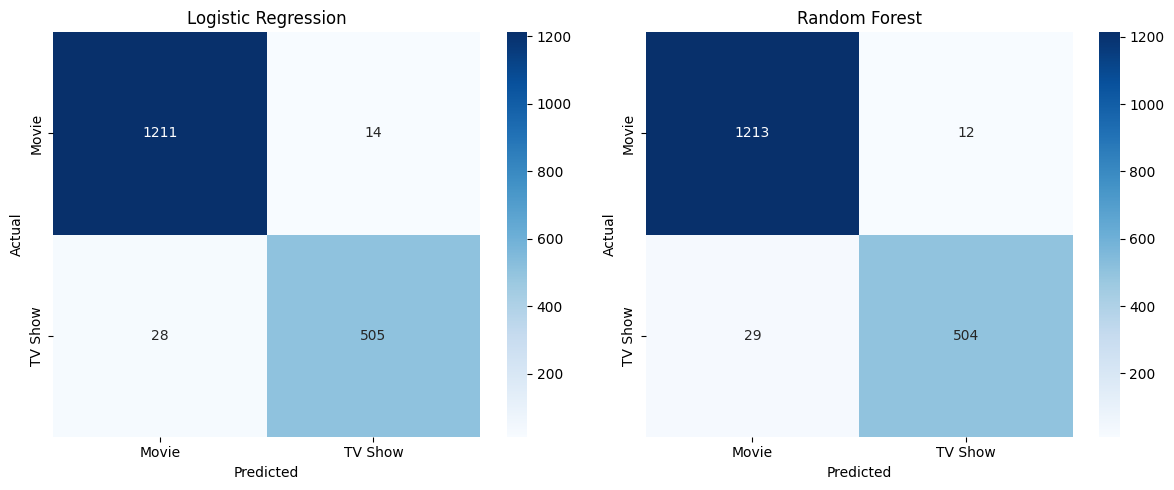

In [11]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=["Movie", "TV Show"]
)

random_forest_cm = confusion_matrix(
    y_test,
    random_forest_predictions,
    labels=["Movie", "TV Show"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Movie", "TV Show"],
    yticklabels=["Movie", "TV Show"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    random_forest_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Movie", "TV Show"],
    yticklabels=["Movie", "TV Show"],
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Step 5: Compare model accuracy

The Logistic Regression and Random Forest models are compared using the evaluation metrics calculated on the same test dataset.

Accuracy provides an overall measure of correct classifications, while precision, recall, and F1-score provide additional information about how well the models classify each class.

The model with the strongest overall performance will be selected based on the evaluation results rather than model complexity alone.

In [12]:
model_comparison = evaluation_results.copy()

model_comparison = model_comparison.sort_values(
    by=["accuracy", "f1_score"],
    ascending=False
)

display(model_comparison)

,model,accuracy,precision,recall,f1_score
1,Random Forest,0.9767,0.9767,0.9456,0.9609
0,Logistic Regression,0.9761,0.9730,0.9475,0.9601


### Model accuracy comparison

The accuracy scores are visualized to make the performance difference between the two classification models easier to compare.

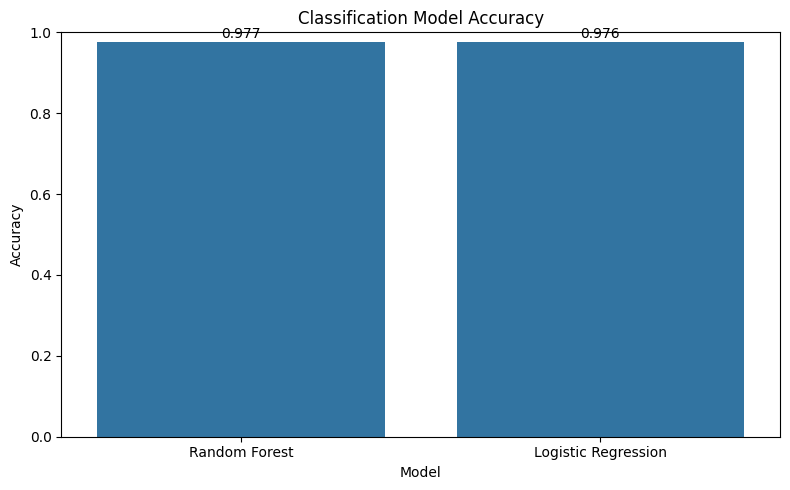

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="model",
    y="accuracy"
)

plt.title("Classification Model Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

for i, value in enumerate(model_comparison["accuracy"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Interpretation of Results

Both classification models performed strongly on the held-out test data.

Random Forest achieved the highest overall accuracy at 97.67%, compared with 97.61% for Logistic Regression. Random Forest also achieved a slightly higher precision of 0.9767 and F1-score of 0.9609.

Logistic Regression achieved a slightly higher recall for the TV Show class, at 0.9475 compared with 0.9456 for Random Forest. This indicates that Logistic Regression identified a slightly larger proportion of the actual TV Shows, although the difference was very small.

Overall, the two models produced very similar results. Random Forest was selected as the best-performing model because it achieved the highest accuracy and F1-score, but the improvement over Logistic Regression was marginal.

The results also show that a relatively simple Logistic Regression model can achieve almost the same performance as the more complex Random Forest model for this classification problem.

## Task 5 Summary

A binary classification model was developed to predict whether a Netflix title is a Movie or a TV Show using available content features.

The selected features included release year, rating, country, category information, director information, audience classification, and year added. Duration-related variables were excluded because they are closely tied to the target variable and could lead to data leakage.

The dataset was divided into training and testing sets using an 80/20 stratified split. Logistic Regression and Random Forest were then trained using Scikit-Learn pipelines that handled feature preprocessing and categorical encoding.

Both models performed strongly on the unseen test data. Random Forest achieved the best overall accuracy at 97.67% and an F1-score of 0.9609, while Logistic Regression achieved an accuracy of 97.61% and an F1-score of 0.9601.

Random Forest was therefore selected as the best-performing model, although its improvement over Logistic Regression was very small.

This task demonstrated the complete classification workflow, including feature selection, data preparation, train/test splitting, model training, performance evaluation, and model comparison.

### Key Limitation

The classification results should be interpreted within the context of this dataset.

The model predicts whether a title is a Movie or TV Show using metadata features from the Netflix catalogue. The high accuracy does not mean that the model would perform equally well on every Netflix dataset or on future content.

In addition, the selected features are catalogue metadata rather than detailed information about the underlying content. The model therefore demonstrates classification performance on this specific dataset rather than providing a general solution for all Netflix content.

## Save the Final Model

The Random Forest pipeline is saved so that the trained model and its preprocessing steps can be reused later without retraining the model from scratch.

In [14]:
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

print("Models directory ready:", models_dir.resolve())

Models directory ready: /home/danvas/auspify-internship/models


In [15]:
import joblib

model_path = models_dir / "netflix_type_classifier_rf.pkl"

if model_path.exists():
    print(f"Model already exists, skipping save: {model_path.resolve()}")
else:
    joblib.dump(
        random_forest_model,
        model_path
    )
    print(f"Random Forest model saved to: {model_path.resolve()}")

Model already exists, skipping save: /home/danvas/auspify-internship/models/netflix_type_classifier_rf.pkl


In [16]:
print("Model file exists:", model_path.exists())
print("Model file size:", round(model_path.stat().st_size / 1024, 2), "KB")

Model file exists: True
Model file size: 28396.92 KB
